In [1]:
#####################################################
# LAB – EDA UNIVARIATE ANALYSIS: AMAZON UK PRODUCTS
#####################################################
#
# In this lab we look at the Amazon UK product dataset from Kaggle and analyse three
# columns one at a time: category, price and stars (the rating).

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/Users/lena/Documents/IRONHACK DATA /Ironhack Data Analysis/WEEK 5/EDA Univariate Analysis Hands On/amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
df.shape

(2443651, 9)

In [4]:
df.info()
print(df.isnull().sum())

# There are no missing values. The rating column is called stars in this file.

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB
uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64


In [5]:
# ===== PART 1 – PRODUCT CATEGORIES =====
#
# --- Frequency table ---

category_counts = df["category"].value_counts()
category_counts

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [6]:
# percentage of listings in each category
category_percent = df["category"].value_counts(normalize=True) * 100
category_percent.head(10)

category
Sports & Outdoors                         34.221949
Beauty                                     0.790293
Handmade Clothing, Shoes & Accessories     0.786896
Bath & Body                                0.781290
Birthday Gifts                             0.776625
Manicure & Pedicure Products               0.775070
Skin Care                                  0.768072
Make-up                                    0.767540
Hair Care                                  0.766681
Fragrances                                 0.759683
Name: proportion, dtype: float64

In [7]:
# top 5 categories
category_counts.head(5)

# The top 5 categories are Sports & Outdoors, Beauty, Handmade Clothing Shoes &
# Accessories, Bath & Body and Birthday Gifts. Sports & Outdoors is much bigger than all
# the others.

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

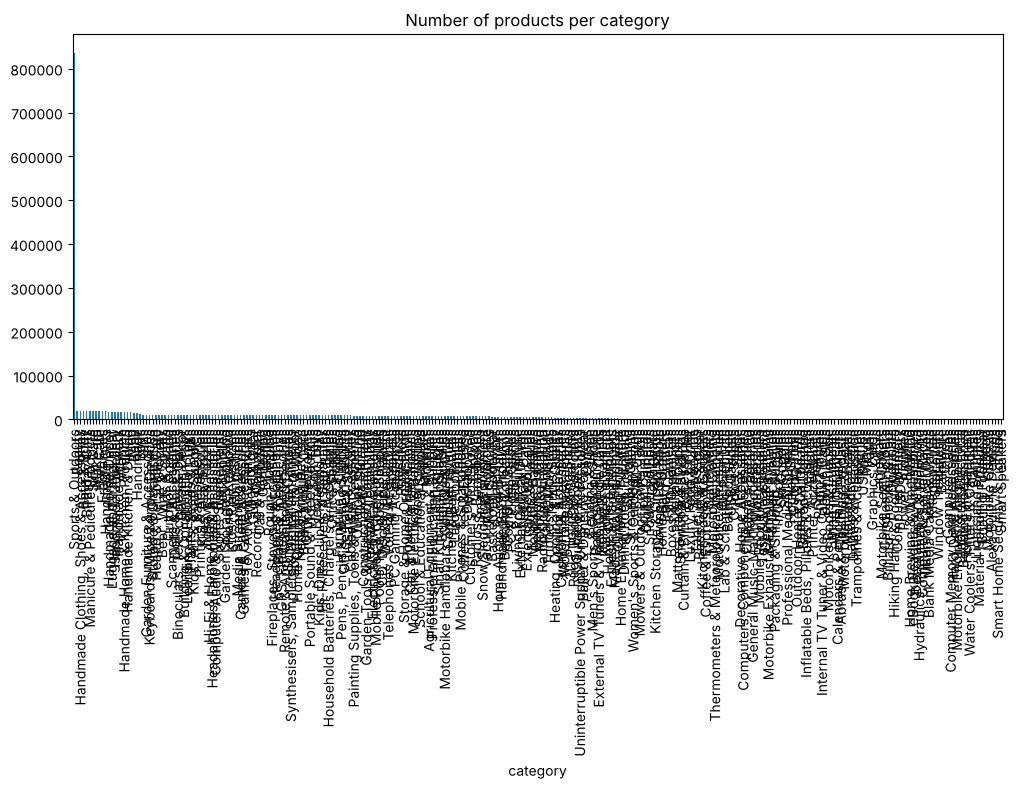

In [8]:
# --- Bar chart ---
# I first tried to plot all the categories:

category_counts.plot(kind="bar", figsize=(12, 5))
plt.title("Number of products per category")
plt.show()

# There are 296 categories so the labels can't be read. I will only plot the top 20.

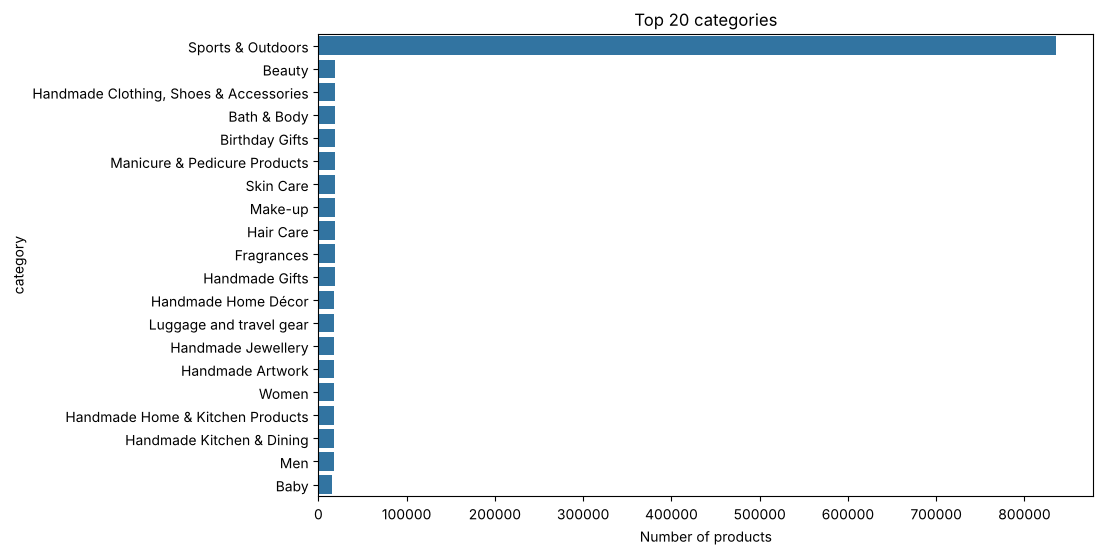

In [9]:
top20 = category_counts.head(20)

plt.figure(figsize=(10, 6))
sns.barplot(x=top20.values, y=top20.index)
plt.title("Top 20 categories")
plt.xlabel("Number of products")
plt.show()

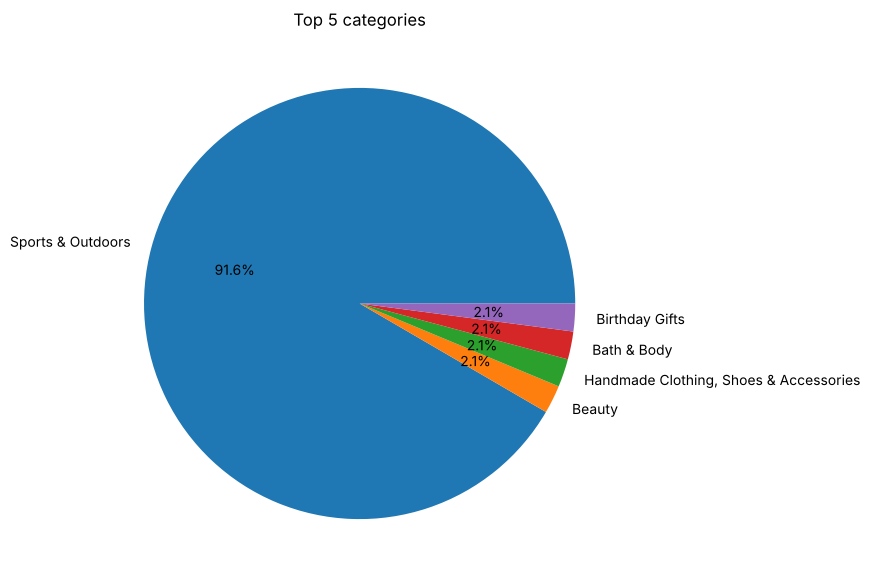

In [10]:
# --- Pie chart ---

top5 = category_counts.head(5)

plt.figure(figsize=(7, 7))
plt.pie(top5, labels=top5.index, autopct="%1.1f%%")
plt.title("Top 5 categories")
plt.show()

# Yes, one category dominates: Sports & Outdoors is about 92% of the top 5 and about 34%
# of all the products in the dataset. The other categories in the top 5 each have only
# around 19,000 products.

In [11]:
# ===== PART 2 – PRICE =====
#
# --- Mean, median, mode ---

print("Mean:", df["price"].mean())
print("Median:", df["price"].median())
print("Mode:", df["price"].mode()[0])

# The average price is about £89, but the median is only about £19 and the most common
# price is £9.99. The mean is much higher than the median, so there must be some very
# expensive products that are increasing the mean.

Mean: 89.24380943923661
Median: 19.09
Mode: 9.99


In [12]:
# most common prices
df["price"].value_counts().head(10)

# The most common prices all end in .99 (£9.99, £12.99, £8.99, ...). Sellers use
# "psychological" prices that look cheaper than the round number.

price
9.99     48922
12.99    38823
8.99     34058
7.99     33632
14.99    32570
6.99     31948
5.99     27818
19.99    27436
11.99    25488
10.99    25172
Name: count, dtype: int64

In [13]:
# --- Variance, standard deviation, range, IQR ---

print("Variance:", df["price"].var())
print("Standard deviation:", df["price"].std())
print("Range:", df["price"].max() - df["price"].min())

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1, "Q3:", Q3, "IQR:", IQR)

Variance: 119445.48532254901
Standard deviation: 345.60886175349873
Range: 100000.0
Q1: 9.99 Q3: 45.99 IQR: 36.0


In [14]:
df["price"].describe()

# The prices are very spread out. The standard deviation is about £346, which is much
# bigger than the mean, and the range is £100,000. But the IQR is only £36 (between £9.99
# and £45.99), so most products are actually close together and only a few are very
# expensive.

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

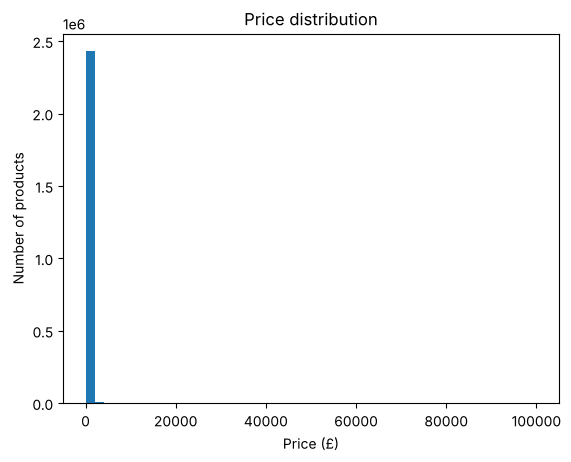

In [15]:
# --- Histogram ---

plt.hist(df["price"], bins=50)
plt.title("Price distribution")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.show()

# This histogram is hard to read. Almost all the products are in the first bar, because
# the x-axis goes up to £100,000 because of a few very expensive products. To fix it I can
# only plot the products under a certain price, for example the outlier limit Q3 + 1.5 ×
# IQR.

Upper limit: 99.99


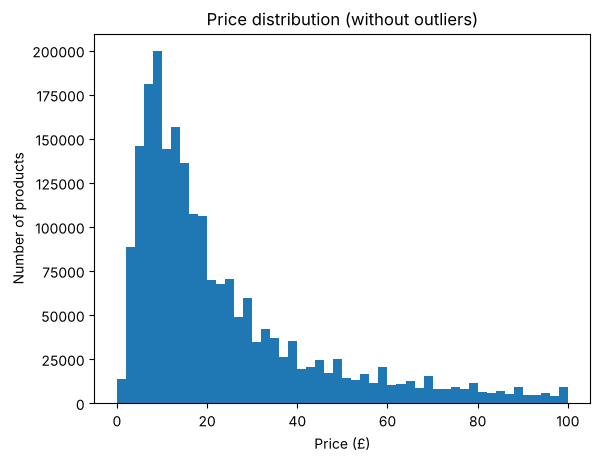

In [16]:
upper_limit = Q3 + 1.5 * IQR
print("Upper limit:", round(upper_limit, 2))

cheap = df[df["price"] <= upper_limit]

plt.hist(cheap["price"], bins=50)
plt.title("Price distribution (without outliers)")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.show()

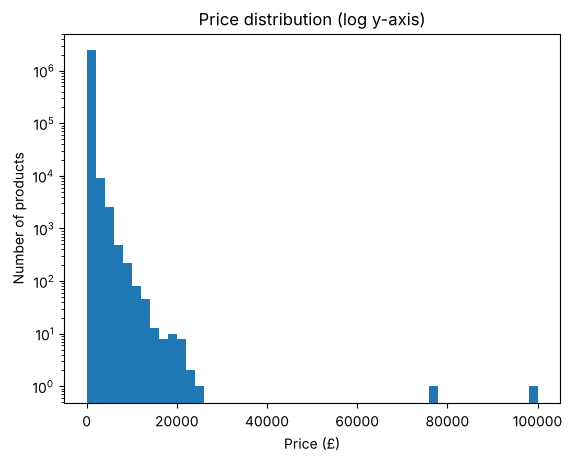

In [17]:
# Now it is easier to see that most products cost between about £5 and £20. Another
# solution is to use a log scale:

plt.hist(df["price"], bins=50, log=True)
plt.title("Price distribution (log y-axis)")
plt.xlabel("Price (£)")
plt.ylabel("Number of products")
plt.show()

# With the log scale on the y-axis we can now see the small bars for the expensive
# products, which were invisible before. Most products are still in the first bar, so
# for the cheap products the chart without outliers is better.

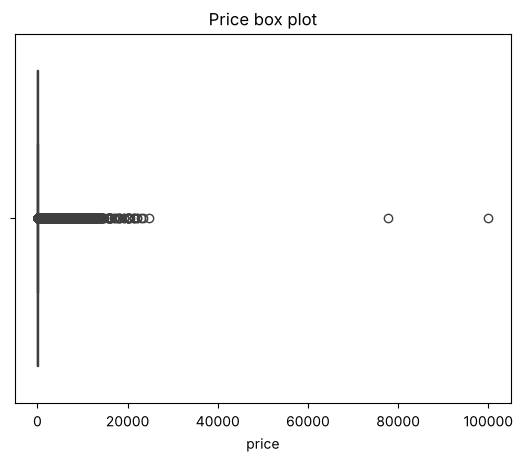

In [18]:
# --- Box plot ---

sns.boxplot(x=df["price"])
plt.title("Price box plot")
plt.show()

In [19]:
outliers = df[df["price"] > upper_limit]
print("Number of outliers:", len(outliers))
print("Percent of outliers:", len(outliers) / len(df) * 100)

# The box is very small and mostly concentrated on the left and there are a lot of outlier points. So
# yes, some products are priced much higher than the rest (about 13% of products are above
# £100).

Number of outliers: 327688
Percent of outliers: 13.409770871536075


In [20]:
# ===== PART 3 – RATINGS =====
#
# --- Mean, median, mode ---

print("Mean:", df["stars"].mean())
print("Median:", df["stars"].median())
print("Mode:", df["stars"].mode()[0])

Mean: 2.152836472966066
Median: 0.0
Mode: 0.0


In [21]:
# These results are strange: the median and the mode are 0. I checked how many products
# have 0 stars:

print((df["stars"] == 0).sum())
print(df[df["stars"] == 0]["reviews"].max())

# Half of the products have 0 stars, and all of them have 0 reviews. So 0 means the
# product has no rating yet, not that customers gave it 0 stars. I will also calculate the
# statistics only for products that have a rating.

1225641
0


In [22]:
rated = df[df["stars"] > 0]

print("Mean:", rated["stars"].mean())
print("Median:", rated["stars"].median())
print("Mode:", rated["stars"].mode()[0])

# For products with a rating, customers usually give good ratings: mean 4.3, median 4.4,
# most common 4.5.

Mean: 4.319160762226911
Median: 4.4
Mode: 4.5


In [23]:
# --- Variance, standard deviation, IQR ---

print("All products:")
print("Variance:", df["stars"].var())
print("Std:", df["stars"].std())
print("IQR:", df["stars"].quantile(0.75) - df["stars"].quantile(0.25))

print()
print("Rated products only:")
print("Variance:", rated["stars"].var())
print("Std:", rated["stars"].std())
print("IQR:", rated["stars"].quantile(0.75) - rated["stars"].quantile(0.25))

# With all products the variation looks big (std 2.2) but this is only because of the
# zeros. For rated products the std is only 0.56 and the IQR is 0.5 (from 4.1 to 4.6), so
# the ratings are quite consistent.

All products:
Variance: 4.817434029796864
Std: 2.194865378513421
IQR: 4.4

Rated products only:
Variance: 0.3083433752387284
Std: 0.5552867504620729
IQR: 0.5


In [24]:
# --- Skewness and kurtosis ---

print("All products - skewness:", df["stars"].skew(), "kurtosis:", df["stars"].kurtosis())
print("Rated products - skewness:", rated["stars"].skew(), "kurtosis:", rated["stars"].kurtosis())

# For rated products the skewness is about -2.4, so the distribution is skewed to the
# left: most ratings are high and there is a tail of a few low ratings. The kurtosis is
# about 9.8, which is much higher than a normal distribution (0), so there is a sharp
# peak. The ratings are not normally distributed.
#
# For all products the skewness is almost 0, but this doesn't mean the data is normal.
# There are two groups (0 and 4–5 stars), so the kurtosis is negative (-1.9).

All products - skewness: 0.08120735761080881 kurtosis: -1.9260061280432994
Rated products - skewness: -2.379568112212799 kurtosis: 9.78193769066435


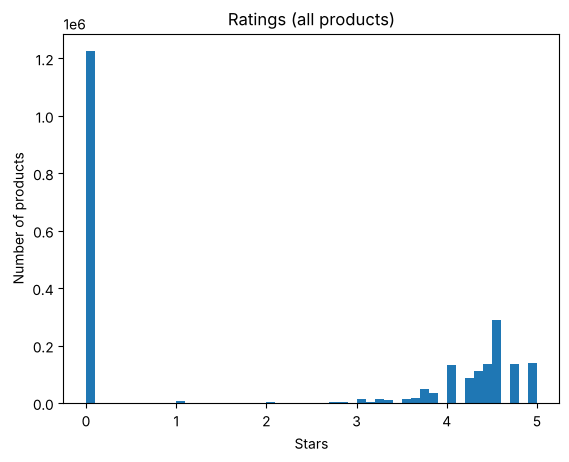

In [25]:
# --- Histogram ---

plt.hist(df["stars"], bins=50)
plt.title("Ratings (all products)")
plt.xlabel("Stars")
plt.ylabel("Number of products")
plt.show()

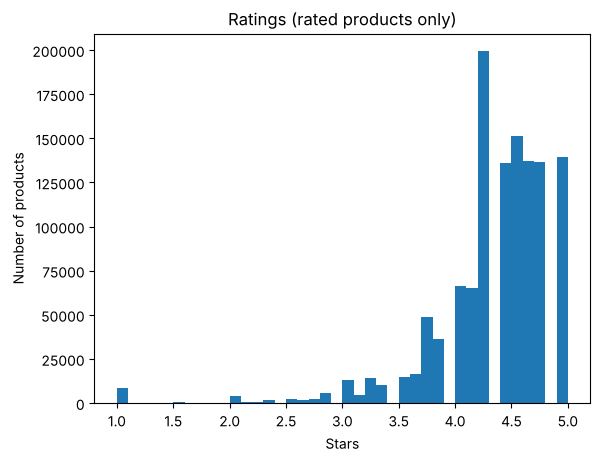

In [26]:
plt.hist(rated["stars"], bins=40)
plt.title("Ratings (rated products only)")
plt.xlabel("Stars")
plt.ylabel("Number of products")
plt.show()

# Most ratings are between 4 and 5 stars, and very few products have less than 3 stars.
# The highest bar is around 4.2-4.3, but I think this is because some bars contain two
# rating values (the ratings go up in steps of 0.1 and the bins don't match exactly).
# The mode I calculated before says the most common single rating is 4.5.

In [27]:
# ===== REPORT =====
#
# Categories. The dataset has about 2.4 million products in 296 categories. Sports &
# Outdoors is by far the biggest category with 836,265 products (34%). The next ones
# (Beauty, Handmade Clothing Shoes & Accessories, Bath & Body, Birthday Gifts) have only
# about 19,000 each. So Sports & Outdoors dominates the listings, and there will be a lot
# of competition there. This could also be because of how the data was collected. Smaller
# categories could be easier for a new seller to stand out in.
#
# Prices. Most products are cheap. The median price is £19.09 and the most common price is
# £9.99, and half of the products cost between £9.99 and £45.99. The mean (£89.24) is a
# lot higher than the median because of a few very expensive products (up to £100,000).
# About 13% of products are outliers above £100. Because of this, the median is a better
# measure of a typical price than the mean, and expensive products should be analysed
# separately. Prices like £9.99, £12.99 and £8.99 are very common, so sellers use prices
# ending in .99.
#
# Ratings. Half of the products have no rating yet (0 stars, 0 reviews). The products that
# have ratings are rated well: mean 4.3, median 4.4, most common 4.5, and the ratings are
# skewed to the left with a sharp peak. So a good rating is normal on Amazon, and a
# product with less than 4 stars will look worse than most others. For new products it is
# important to get the first reviews, because half of the products have none.
#
# Next steps. It would be interesting to compare price and rating between categories, and
# to see if best sellers have different prices or ratings.